Practical 04

Part A: Load and Split

Q1

Dataset Shape: (387, 34)

Class Counts:
target
0    357
1     30
Name: count, dtype: int64

Class Percentages:
target
0    92.248062
1     7.751938
Name: proportion, dtype: float64


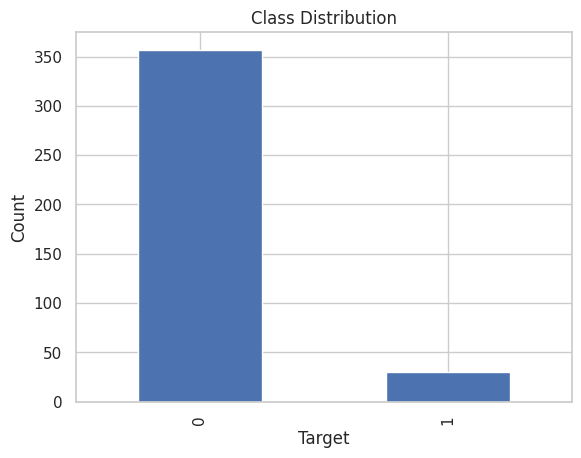

Training Class Distribution:
target
0    285
1     24
Name: count, dtype: int64

Testing Class Distribution:
target
0    72
1     6
Name: count, dtype: int64


In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")

data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

# Change target: 1 = malignant, 0 = benign
df["target"] = 1 - df["target"]

# Keep only 30 malignant samples
malignant = df[df["target"] == 1].sample(30, random_state=42)
benign = df[df["target"] == 0]

df = pd.concat([benign, malignant])
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Add artificial features
rng = np.random.RandomState(42)
df["const_feat"] = 5.0
df["near_const"] = (rng.rand(len(df)) < 0.005).astype(int)
df["noise"] = rng.randn(len(df))

# (a) Shape and class distribution
print("Dataset Shape:", df.shape)
print("\nClass Counts:")
print(df["target"].value_counts())

print("\nClass Percentages:")
print(df["target"].value_counts(normalize=True) * 100)

df["target"].value_counts().plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()

# (b) Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

# (c) Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# (d) Display class distributions
print("Training Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())


Stratification maintains the same class proportions in both training and testing sets. It is important because this dataset is imbalanced. It ensures that both sets contain a similar proportion of minority and majority classes.

Part B: Feature Selection

Q2

Removed features (Scaled):
['concavity error', 'fractal dimension error', 'const_feat', 'near_const']

Removed features (Unscaled):
['mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst smoothness', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'const_feat', 'near_const']

Top 10 Features:
worst area              0.728340
worst perimeter         0.709087
worst radius            0.685449
mean concave points     0.684307
mean area               0.660899
worst concave points    0.654000
area error              0.633103
mean perimeter          0.626429
mean radius             0.602033
mean concavity          0.557286
dtype: float64


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


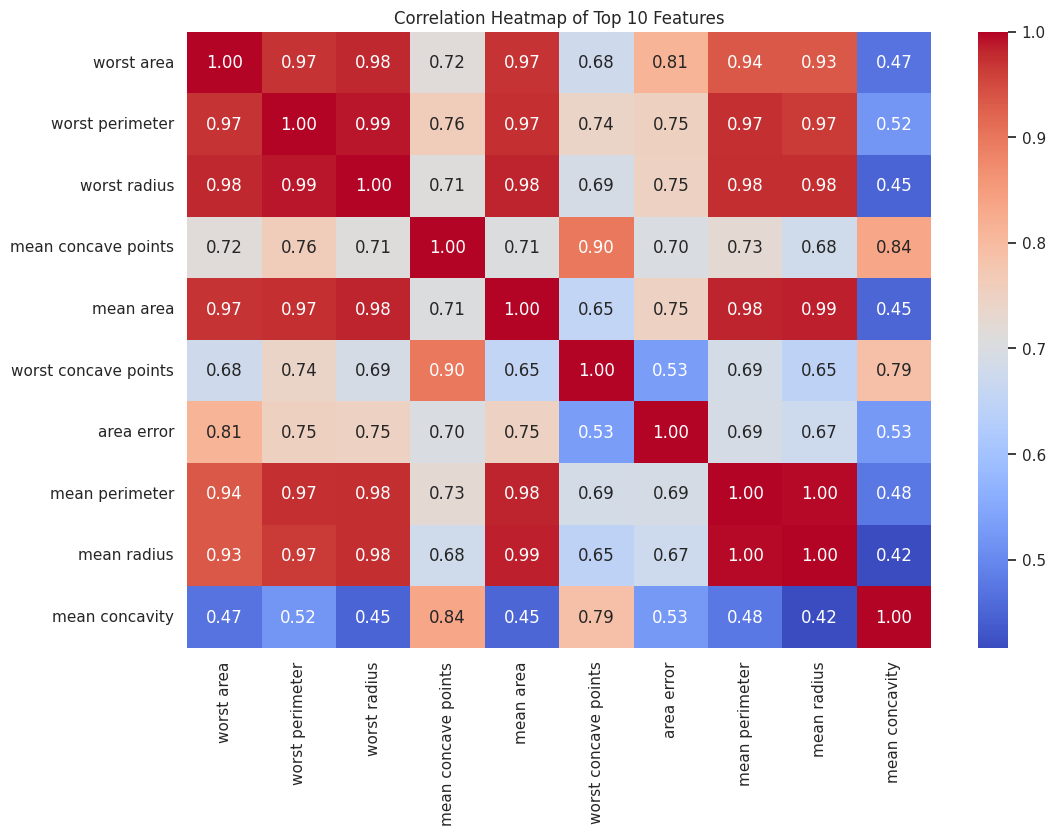


Highly Correlated Pairs:
[('worst area', 'worst perimeter'), ('worst area', 'worst radius'), ('worst area', 'mean area'), ('worst area', 'mean perimeter'), ('worst area', 'mean radius'), ('worst perimeter', 'worst radius'), ('worst perimeter', 'mean area'), ('worst perimeter', 'mean perimeter'), ('worst perimeter', 'mean radius'), ('worst radius', 'mean area'), ('worst radius', 'mean perimeter'), ('worst radius', 'mean radius'), ('mean area', 'mean perimeter'), ('mean area', 'mean radius'), ('mean perimeter', 'mean radius')]

Features to Remove:
{'mean radius', 'mean area', 'worst radius', 'mean perimeter', 'worst perimeter'}


In [14]:

from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import VarianceThreshold

# (a) Min-Max scaling
mm_scaler = MinMaxScaler()

X_train_mm = pd.DataFrame(
    mm_scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_mm = pd.DataFrame(
    mm_scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# (b) Variance threshold on scaled data
vt_scaled = VarianceThreshold(threshold=0.01)
vt_scaled.fit(X_train_mm)

removed_scaled = X_train_mm.columns[~vt_scaled.get_support()]
print("Removed features (Scaled):")
print(list(removed_scaled))

# (c) Variance threshold on unscaled data
vt_unscaled = VarianceThreshold(threshold=0.01)
vt_unscaled.fit(X_train)

removed_unscaled = X_train.columns[~vt_unscaled.get_support()]
print("\nRemoved features (Unscaled):")
print(list(removed_unscaled))

# (d) Pearson correlation with target
correlations = X_train_mm.corrwith(y_train).abs()
top10 = correlations.sort_values(ascending=False).head(10)

print("\nTop 10 Features:")
print(top10)

# (e) Correlation heatmap
top10_features = top10.index

plt.figure(figsize=(12, 8))
sns.heatmap(
    X_train_mm[top10_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap of Top 10 Features")
plt.show()

# Find highly correlated feature pairs
corr_matrix = X_train_mm[top10_features].corr()

high_pairs = []
for i in range(len(top10_features)):
    for j in range(i + 1, len(top10_features)):
        f1 = top10_features[i]
        f2 = top10_features[j]

        if abs(corr_matrix.loc[f1, f2]) > 0.90:
            high_pairs.append((f1, f2))

print("\nHighly Correlated Pairs:")
print(high_pairs)

# Remove one feature from each pair
drop_features = set()

for f1, f2 in high_pairs:
    if correlations[f1] >= correlations[f2]:
        drop_features.add(f2)
    else:
        drop_features.add(f1)

print("\nFeatures to Remove:")
print(drop_features)


1. Variance depends on the scale because features with larger numerical ranges can have larger variances.



2. Scaling changes the variance of features. Therefore, the removed features can be different.



3. One limitation of Pearson correlation is that it only detects linear relationships. It may not identify non-linear relationships.

Q3

In [15]:

from sklearn.feature_selection import (
    SelectKBest,
    chi2,
    mutual_info_classif,
    f_classif
)

# Remove features dropped in Q2(b)
X_train_q3 = X_train_mm.drop(columns=removed_scaled)

# Chi-Square
chi_selector = SelectKBest(score_func=chi2, k=10)
chi_selector.fit(X_train_q3, y_train)

chi_scores = pd.Series(
    chi_selector.scores_,
    index=X_train_q3.columns
).sort_values(ascending=False)

# Mutual Information
mi_selector = SelectKBest(
    score_func=mutual_info_classif,
    k=10
)
mi_selector.fit(X_train_q3, y_train)

mi_scores = pd.Series(
    mi_selector.scores_,
    index=X_train_q3.columns
).sort_values(ascending=False)

# ANOVA
anova_selector = SelectKBest(score_func=f_classif, k=10)
anova_selector.fit(X_train_q3, y_train)

anova_scores = pd.Series(
    anova_selector.scores_,
    index=X_train_q3.columns
).sort_values(ascending=False)

# (a) Display top 10 features
print("Top 10 Chi-Square Features:")
print(chi_scores.head(10))

print("\nTop 10 Mutual Information Features:")
print(mi_scores.head(10))

print("\nTop 10 ANOVA Features:")
print(anova_scores.head(10))

# (b) Common features
chi_top = set(chi_scores.head(10).index)
mi_top = set(mi_scores.head(10).index)
anova_top = set(anova_scores.head(10).index)

common_features = chi_top & mi_top & anova_top

print("\nFeatures Selected by All Three Methods:")
print(common_features)

# (c) Noise feature rank
for name, scores in [
    ("Chi-Square", chi_scores),
    ("Mutual Information", mi_scores),
    ("ANOVA", anova_scores)
]:
    if "noise" in scores.index:
        rank = scores.rank(ascending=False, method="min")["noise"]
        print(f"{name} noise rank: {int(rank)}")
    else:
        print(f"{name}: noise feature was removed before selection")


Top 10 Chi-Square Features:
mean concave points     18.293907
mean concavity          15.422267
worst area              14.674053
worst concave points    14.305486
area error              13.157306
worst perimeter         11.946271
worst concavity         11.561250
mean area               10.923791
worst radius            10.154148
mean perimeter           8.114410
dtype: float64

Top 10 Mutual Information Features:
worst concave points    0.197603
worst perimeter         0.195071
worst area              0.179204
worst radius            0.175659
mean concave points     0.171840
mean perimeter          0.163711
mean radius             0.146494
mean area               0.144505
area error              0.128644
worst concavity         0.124048
dtype: float64

Top 10 ANOVA Features:
worst area              346.858025
worst perimeter         310.462322
worst radius            272.071519
mean concave points     270.366830
mean area               238.087369
worst concave points    229.446481
a

a) Chi-Square uses non-negative values to calculate the relationship between features and the target. Negative values are not suitable for this calculation.

b) Mutual Information can detect both linear and non-linear relationships.

c) ANOVA F-test assumes that the feature values have different means across the target classes. It also assumes normally distributed values within groups and equal variances.

Q4

RFE Selected Features:
['mean area', 'mean concave points', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concave points', 'worst symmetry']

L1 Selected Features:
['mean concavity', 'mean concave points', 'area error', 'worst texture', 'worst area', 'worst smoothness', 'worst concave points', 'worst symmetry']

Random Forest Selected Features:
['worst concave points', 'worst perimeter', 'worst area', 'worst radius', 'mean concave points', 'mean radius', 'mean perimeter', 'mean area', 'area error', 'worst concavity']

Common Features (ANOVA, RFE, L1):
{'mean concave points', 'worst area', 'area error', 'worst concave points'}


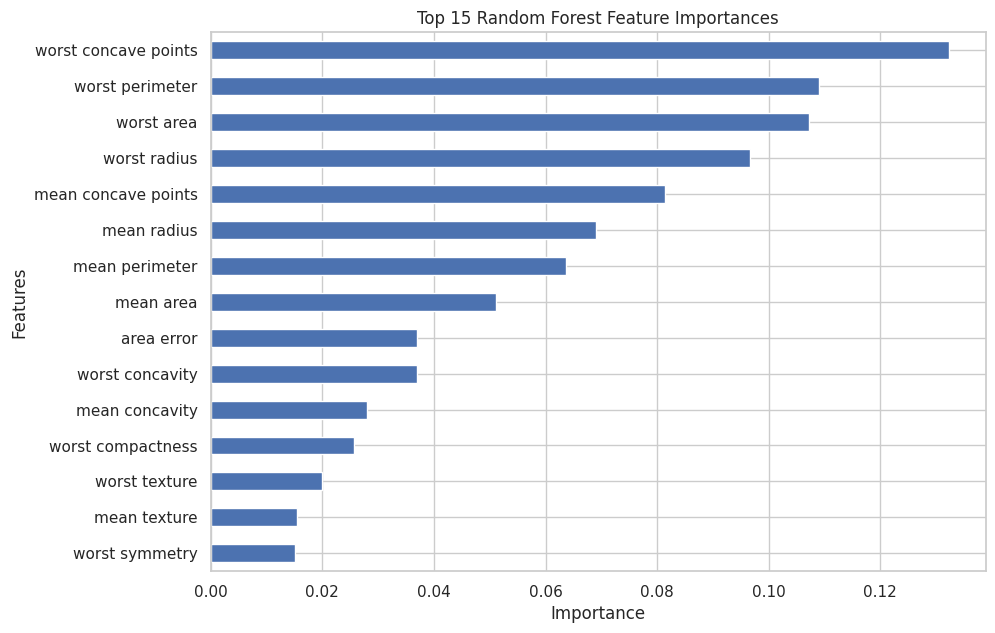


Selection Times:
ANOVA: 0.003747701644897461 seconds
RFE: 0.11870241165161133 seconds
L1: 0.006563663482666016 seconds


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [30 31] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [16]:

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import time

# Standardisation
scaler = StandardScaler()

X_train_s = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_s = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# (a) RFE
start = time.time()

rfe = RFE(
    estimator=LogisticRegression(max_iter=1000),
    n_features_to_select=10
)
rfe.fit(X_train_s, y_train)

wrapper_features = X_train_s.columns[rfe.support_]
rfe_time = time.time() - start

print("RFE Selected Features:")
print(list(wrapper_features))

# (b) L1 Regularisation
start = time.time()

l1 = LogisticRegression(
    penalty="l1",
    solver="liblinear",
    C=0.5,
    max_iter=1000
)

l1_sel = SelectFromModel(l1)
l1_sel.fit(X_train_s, y_train)

l1_features = X_train_s.columns[l1_sel.get_support()]
l1_time = time.time() - start

print("\nL1 Selected Features:")
print(list(l1_features))

# Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train_s, y_train)

rf_imp = pd.Series(
    rf.feature_importances_,
    index=X_train_s.columns
)

rf_features = rf_imp.sort_values(
    ascending=False
).head(10).index

print("\nRandom Forest Selected Features:")
print(list(rf_features))

# (c) Common features: ANOVA, RFE and L1
common_q4 = (
    set(anova_scores.head(10).index)
    & set(wrapper_features)
    & set(l1_features)
)

print("\nCommon Features (ANOVA, RFE, L1):")
print(common_q4)

# (b) Random Forest importance plot
plt.figure(figsize=(10, 7))

rf_imp.sort_values().tail(15).plot(kind="barh")

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

# (d) ANOVA time
start = time.time()

anova_selector = SelectKBest(score_func=f_classif, k=10)
anova_selector.fit(X_train_s, y_train)

anova_time = time.time() - start

print("\nSelection Times:")
print("ANOVA:", anova_time, "seconds")
print("RFE:", rfe_time, "seconds")
print("L1:", l1_time, "seconds")


ANOVA is generally the fastest method because it evaluates each feature independently. RFE is more computationally expensive because it repeatedly trains models and removes features. L1 is an embedded method that selects features using regularisation.

Q5

In [17]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.base import clone

# Define feature sets
feature_sets = {
    "All Features": list(X_train_s.columns),
    "Filter (ANOVA)": list(anova_scores.head(10).index),
    "Filter (Mutual Info)": list(mi_scores.head(10).index),
    "Wrapper (RFE)": list(wrapper_features),
    "Embedded (L1)": list(l1_features)
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, features in feature_sets.items():

    Xtr = X_train_s[features]
    Xte = X_test_s[features]

    model = LogisticRegression(max_iter=1000)

    # 5-fold cross-validation
    cv_scores = cross_val_score(
        model,
        Xtr,
        y_train,
        cv=cv,
        scoring="f1"
    )

    # Train and test model
    model.fit(Xtr, y_train)

    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1]

    test_f1 = f1_score(y_test, y_pred)
    test_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Feature Set": name,
        "No. of Features": len(features),
        "CV F1": cv_scores.mean(),
        "Test F1": test_f1,
        "Test ROC-AUC": test_auc
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


         Feature Set  No. of Features  CV F1  Test F1  Test ROC-AUC
        All Features               33 0.9270      1.0           1.0
      Filter (ANOVA)               10 0.8992      1.0           1.0
Filter (Mutual Info)               10 0.8992      1.0           1.0
       Wrapper (RFE)               10 0.9270      1.0           1.0
       Embedded (L1)                8 0.9556      1.0           1.0


a) The method with a high F1-score and fewer features provides the best trade-off. The results table can be used to identify it.

b)
- Filter methods are generally the fastest because they evaluate features independently.
- Wrapper methods are generally the most computationally expensive because they repeatedly train models.

c) Filter methods evaluate each feature separately. Therefore, they may select two features that contain similar information.

d) Accuracy can be high even when the model fails to identify most minority-class samples. Therefore, F1-score, precision and recall are more useful.

Part C: PCA for Feature Extraction

Q6

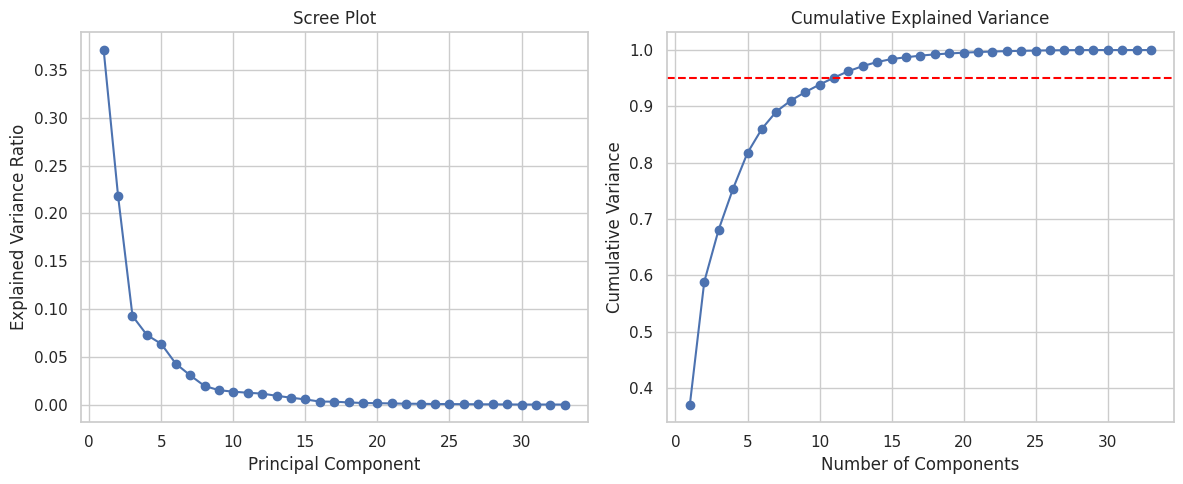

Components needed for 95% variance: 11
Original Training Shape: (309, 33)
New Training Shape: (309, 11)
Original Testing Shape: (78, 33)
New Testing Shape: (78, 11)


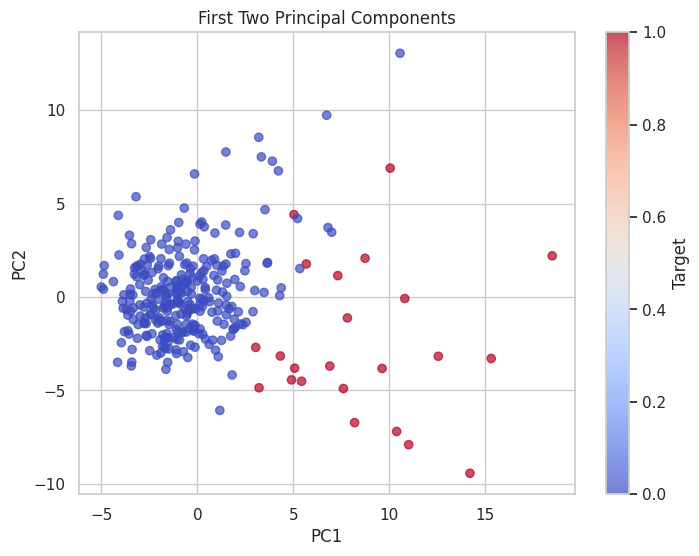

Top 5 Features for PC1:
mean concave points     0.276241
mean concavity          0.265624
worst concave points    0.264962
mean compactness        0.250905
worst concavity         0.240716
dtype: float64

Model Comparison:
           Model  Test F1  Test ROC-AUC
0  Full Features      1.0           1.0
1            PCA      1.0           1.0


In [18]:

from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, roc_auc_score

# (a) Fit PCA on standardised training data
pca_full = PCA()
pca_full.fit(X_train_s)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Scree plot and cumulative variance
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)
plt.title("Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")

plt.subplot(1, 2, 2)
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(y=0.95, color="red", linestyle="--")
plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")

plt.tight_layout()
plt.show()

# (b) Components needed for 95% variance
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Components needed for 95% variance:", n_components)

# (c) PCA with 95% variance
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

print("Original Training Shape:", X_train_s.shape)
print("New Training Shape:", X_train_pca.shape)

print("Original Testing Shape:", X_test_s.shape)
print("New Testing Shape:", X_test_pca.shape)

# (d) First two principal components
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="coolwarm",
    alpha=0.7
)

plt.title("First Two Principal Components")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="Target")
plt.show()

# (e) Top 5 original features for PC1
pc1_loadings = pd.Series(
    pca.components_[0],
    index=X_train_s.columns
)

top5_pc1 = pc1_loadings.abs().sort_values(
    ascending=False
).head(5)

print("Top 5 Features for PC1:")
print(top5_pc1)

# (f) Logistic Regression using PCA features
pca_model = LogisticRegression(max_iter=1000)

pca_model.fit(X_train_pca, y_train)

pca_pred = pca_model.predict(X_test_pca)
pca_prob = pca_model.predict_proba(X_test_pca)[:, 1]

pca_f1 = f1_score(y_test, pca_pred)
pca_auc = roc_auc_score(y_test, pca_prob)

# Full-feature model for comparison
full_model = LogisticRegression(max_iter=1000)
full_model.fit(X_train_s, y_train)

full_pred = full_model.predict(X_test_s)
full_prob = full_model.predict_proba(X_test_s)[:, 1]

full_f1 = f1_score(y_test, full_pred)
full_auc = roc_auc_score(y_test, full_prob)

comparison = pd.DataFrame({
    "Model": ["Full Features", "PCA"],
    "Test F1": [full_f1, pca_f1],
    "Test ROC-AUC": [full_auc, pca_auc]
})

print("\nModel Comparison:")
print(comparison.round(4))


a) PCA is affected by the variance of features. Standardisation gives all features a similar scale and prevents large-scale features from dominating the results.

b) PCA must be fitted only on the training set to prevent data leakage. The test set is transformed using the PCA model fitted on the training set.

c) Two differences between feature selection and PCA:
1. Feature selection chooses existing features, while PCA creates new features called principal components.
2. Feature selection keeps the original meaning of features, while PCA makes interpretation more difficult.

Feature selection is preferred when interpretability is important.

Part D: Data Transformation

Q7


 Original Training Data
                       Min        Max        Mean  Standard Deviation
mean area        143.50000  1747.0000  504.035599          216.663009
mean texture       9.71000    33.8100   18.180712            4.068208
mean smoothness    0.05263     0.1291    0.092994            0.013040

 Original Testing Data
                       Min        Max        Mean  Standard Deviation
mean area        221.80000  1261.0000  511.207692          212.923460
mean texture      10.91000    29.4300   18.689487            4.426038
mean smoothness    0.06576     0.1634    0.094318            0.015475

 Min-Max Training Data
                 Min  Max      Mean  Standard Deviation
mean area        0.0  1.0  0.224843            0.135119
mean texture     0.0  1.0  0.351482            0.168805
mean smoothness  0.0  1.0  0.527841            0.170519

 Min-Max Testing Data
                      Min       Max      Mean  Standard Deviation
mean area        0.048831  0.696913  0.229316         

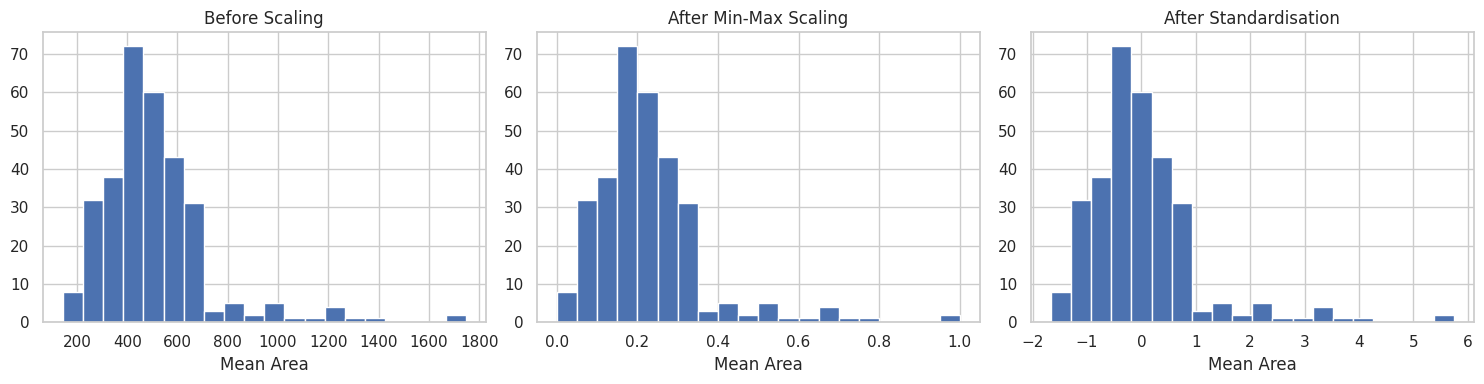

Min-Max Test Values:
Minimum: mean area          0.048831
mean texture       0.049793
mean smoothness    0.171701
dtype: float64
Maximum: mean area          0.696913
mean texture       0.818257
mean smoothness    1.448542
dtype: float64

Values within [0,1]:
mean area           True
mean texture        True
mean smoothness    False
dtype: bool


In [19]:

from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Select three features
features = ["mean area", "mean texture", "mean smoothness"]

X_train_selected = X_train[features]
X_test_selected = X_test[features]

# (a) Min-Max Scaling
minmax = MinMaxScaler()

train_mm = minmax.fit_transform(X_train_selected)
test_mm = minmax.transform(X_test_selected)

# Standard Scaling
standard = StandardScaler()

train_std = standard.fit_transform(X_train_selected)
test_std = standard.transform(X_test_selected)

# Convert into DataFrames
train_mm = pd.DataFrame(
    train_mm, columns=features, index=X_train.index
)
test_mm = pd.DataFrame(
    test_mm, columns=features, index=X_test.index
)

train_std = pd.DataFrame(
    train_std, columns=features, index=X_train.index
)
test_std = pd.DataFrame(
    test_std, columns=features, index=X_test.index
)

# (b) Display statistics
def show_statistics(name, data):
    print("\n", name)
    print(pd.DataFrame({
        "Min": data.min(),
        "Max": data.max(),
        "Mean": data.mean(),
        "Standard Deviation": data.std()
    }))

show_statistics("Original Training Data", X_train_selected)
show_statistics("Original Testing Data", X_test_selected)

show_statistics("Min-Max Training Data", train_mm)
show_statistics("Min-Max Testing Data", test_mm)

show_statistics("Standardised Training Data", train_std)
show_statistics("Standardised Testing Data", test_std)

# (c) Histograms of mean area
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(X_train_selected["mean area"], bins=20)
plt.title("Before Scaling")
plt.xlabel("Mean Area")

plt.subplot(1, 3, 2)
plt.hist(train_mm["mean area"], bins=20)
plt.title("After Min-Max Scaling")
plt.xlabel("Mean Area")

plt.subplot(1, 3, 3)
plt.hist(train_std["mean area"], bins=20)
plt.title("After Standardisation")
plt.xlabel("Mean Area")

plt.tight_layout()
plt.show()

# (d) Check Min-Max test values
print("Min-Max Test Values:")
print("Minimum:", test_mm.min())
print("Maximum:", test_mm.max())

print("\nValues within [0,1]:")
print(((test_mm >= 0) & (test_mm <= 1)).all())


Why may test values be outside [0, 1]?

The MinMaxScaler uses the minimum and maximum values of the training set. If the test set contains values outside the training range, the scaled values may be below 0 or above 1.

Which scaler is more sensitive to outliers?

MinMaxScaler is more sensitive to outliers because extreme values affect the minimum and maximum values.

Q8

Equal Width Bin Edges:
[ 143.5  464.2  784.9 1105.6 1426.3 1747. ]

Equal Frequency Bin Edges:
[ 143.5   358.38  432.    512.2   604.64 1747.  ]

Equal Width Counts:
0.0    150
1.0    137
2.0     13
3.0      7
4.0      2
Name: count, dtype: int64

Equal Frequency Counts:
0.0    62
1.0    61
2.0    61
3.0    63
4.0    62
Name: count, dtype: int64


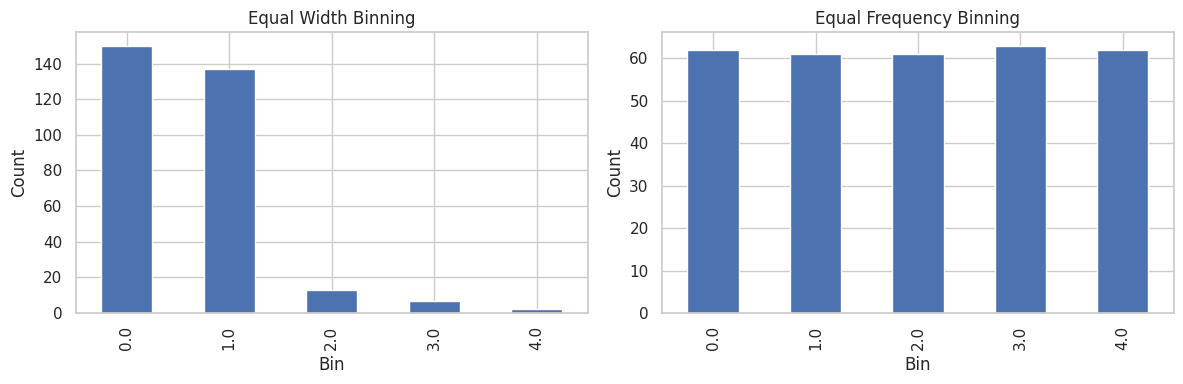


Equal Frequency Bin Table:
   Bin Number             Range  Count
0           0   143.50 - 358.38     62
1           1   358.38 - 432.00     61
2           2   432.00 - 512.20     61
3           3   512.20 - 604.64     63
4           4  604.64 - 1747.00     62

Results for 3 Bins

Strategy: uniform
Bin Edges: [ 143.5  678.  1212.5 1747. ]
Bin Counts:
0.0    274
1.0     27
2.0      8
Name: count, dtype: int64

Strategy: quantile
Bin Edges: [ 143.5         407.06666667  537.5        1747.        ]
Bin Counts:
0.0    103
1.0    103
2.0    103
Name: count, dtype: int64

Results for 10 Bins

Strategy: uniform
Bin Edges: [ 143.5   303.85  464.2   624.55  784.9   945.25 1105.6  1265.95 1426.3
 1586.65 1747.  ]
Bin Counts:
0.0     40
1.0    110
2.0    103
3.0     34
4.0      7
5.0      6
6.0      5
7.0      2
9.0      2
Name: count, dtype: int64

Strategy: quantile
Bin Edges: [ 143.5   289.58  358.38  398.72  432.    466.7   512.2   554.46  604.64
  684.6  1747.  ]
Bin Counts:
0.0    31
1.0  

In [20]:

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.preprocessing import OneHotEncoder

# Select mean area
X_train_area = X_train[["mean area"]]
X_test_area = X_test[["mean area"]]

# (a) Equal-width and equal-frequency with 5 bins
ew = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="uniform"
)

ef = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="quantile"
)

train_ew = ew.fit_transform(X_train_area).ravel()
test_ew = ew.transform(X_test_area).ravel()

train_ef = ef.fit_transform(X_train_area).ravel()
test_ef = ef.transform(X_test_area).ravel()

# (b) Display bin edges
print("Equal Width Bin Edges:")
print(ew.bin_edges_[0])

print("\nEqual Frequency Bin Edges:")
print(ef.bin_edges_[0])

# (c) Count samples in each bin
ew_counts = pd.Series(train_ew).value_counts().sort_index()
ef_counts = pd.Series(train_ef).value_counts().sort_index()

print("\nEqual Width Counts:")
print(ew_counts)

print("\nEqual Frequency Counts:")
print(ef_counts)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
ew_counts.plot(kind="bar")
plt.title("Equal Width Binning")
plt.xlabel("Bin")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
ef_counts.plot(kind="bar")
plt.title("Equal Frequency Binning")
plt.xlabel("Bin")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

# (d) Equal frequency bin table
edges = ef.bin_edges_[0]

bin_table = pd.DataFrame({
    "Bin Number": range(len(edges) - 1),
    "Range": [
        f"{edges[i]:.2f} - {edges[i+1]:.2f}"
        for i in range(len(edges) - 1)
    ],
    "Count": [
        int((train_ef == i).sum())
        for i in range(len(edges) - 1)
    ]
})

print("\nEqual Frequency Bin Table:")
print(bin_table)

# (e) Repeat with 3 and 10 bins
for n in [3, 10]:

    print(f"\nResults for {n} Bins")

    for strategy in ["uniform", "quantile"]:

        discretizer = KBinsDiscretizer(
            n_bins=n,
            encode="ordinal",
            strategy=strategy
        )

        binned = discretizer.fit_transform(
            X_train_area
        ).ravel()

        print("\nStrategy:", strategy)
        print("Bin Edges:", discretizer.bin_edges_[0])
        print("Bin Counts:")
        print(pd.Series(binned).value_counts().sort_index())

# (f) Compare binned mean area and raw mean area

# Raw feature model
raw_model = LogisticRegression(max_iter=1000)
raw_model.fit(X_train_area, y_train)

raw_pred = raw_model.predict(X_test_area)
raw_f1 = f1_score(y_test, raw_pred)

# One-hot encoding of binned values
encoder = OneHotEncoder(handle_unknown="ignore")

train_encoded = encoder.fit_transform(
    train_ef.reshape(-1, 1)
)

test_encoded = encoder.transform(
    test_ef.reshape(-1, 1)
)

binned_model = LogisticRegression(max_iter=1000)
binned_model.fit(train_encoded, y_train)

binned_pred = binned_model.predict(test_encoded)
binned_f1 = f1_score(y_test, binned_pred)

print("\nRaw Mean Area F1:", raw_f1)
print("Binned Mean Area F1:", binned_f1)


a) Equal-width binning can produce very unequal counts because each bin has the same width, but the data may not be evenly distributed.

b) Equal-width binning is more sensitive to outliers because extreme values affect the range and bin widths.

c) One advantage and one disadvantage of discretization:
- Advantage: It simplifies continuous data into groups.
- Disadvantage: It loses some information from the original values.

Part E: Handling Class Imbalance


Q9

In [21]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Train Logistic Regression
baseline_model = LogisticRegression(max_iter=1000)
baseline_model.fit(X_train_s, y_train)

# Predictions
y_pred_base = baseline_model.predict(X_test_s)

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_base))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_base))

# Minority class metrics (class 1)
print("\nMinority Class Metrics:")
print("Accuracy:", accuracy_score(y_test, y_pred_base))
print("Precision:", precision_score(y_test, y_pred_base, pos_label=1))
print("Recall:", recall_score(y_test, y_pred_base, pos_label=1))
print("F1-score:", f1_score(y_test, y_pred_base, pos_label=1))


Confusion Matrix:
[[72  0]
 [ 0  6]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        72
           1       1.00      1.00      1.00         6

    accuracy                           1.00        78
   macro avg       1.00      1.00      1.00        78
weighted avg       1.00      1.00      1.00        78


Minority Class Metrics:
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0


Accuracy looks high because the dataset contains many majority-class samples. The model can predict the majority class correctly while failing to identify many minority-class samples.

In medical diagnosis, this is important because failing to identify malignant cases can lead to serious consequences. Therefore, recall is an important metric.

Q10

Before SMOTE:
target
0    285
1     24
Name: count, dtype: int64

After SMOTE:
target
0    285
1    285
Name: count, dtype: int64

Comparison of Imbalance Methods:
                  Method  Precision  Recall     F1  ROC-AUC
Baseline (no resampling)     1.0000     1.0 1.0000      1.0
       SMOTE (ratio 1.0)     1.0000     1.0 1.0000      1.0
       SMOTE (ratio 0.5)     1.0000     1.0 1.0000      1.0
 class_weight="balanced"     0.8571     1.0 0.9231      1.0


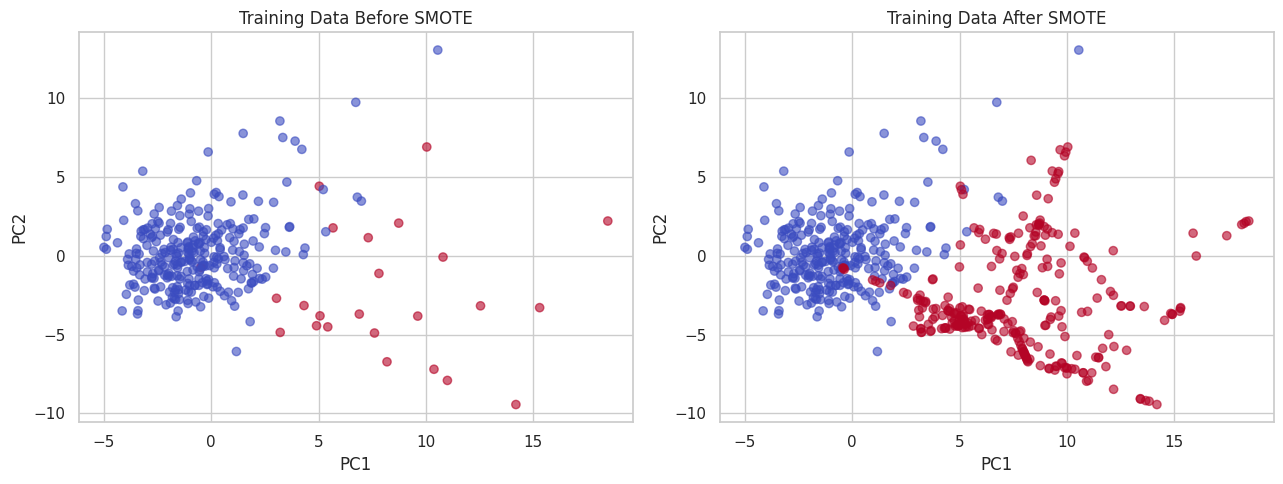

In [22]:

# Install imbalanced-learn if needed
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# (a) Class counts before SMOTE
print("Before SMOTE:")
print(y_train.value_counts())

# SMOTE ratio 1.0
smote_1 = SMOTE(
    sampling_strategy=1.0,
    random_state=42
)

X_train_smote, y_train_smote = smote_1.fit_resample(
    X_train_s, y_train
)

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

# (b) Train Logistic Regression
smote_model = LogisticRegression(max_iter=1000)

smote_model.fit(X_train_smote, y_train_smote)

smote_pred = smote_model.predict(X_test_s)
smote_prob = smote_model.predict_proba(X_test_s)[:, 1]

# (c) Evaluation function
def evaluate_model(name, y_true, predictions, probabilities):
    return {
        "Method": name,
        "Precision": precision_score(
            y_true, predictions, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, pos_label=1, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, pos_label=1, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

# Baseline probabilities
base_prob = baseline_model.predict_proba(X_test_s)[:, 1]

results_imbalance = []

results_imbalance.append(
    evaluate_model(
        "Baseline (no resampling)",
        y_test,
        y_pred_base,
        base_prob
    )
)

results_imbalance.append(
    evaluate_model(
        "SMOTE (ratio 1.0)",
        y_test,
        smote_pred,
        smote_prob
    )
)

# SMOTE ratio 0.5
smote_half = SMOTE(
    sampling_strategy=0.5,
    random_state=42
)

X_train_half, y_train_half = smote_half.fit_resample(
    X_train_s, y_train
)

model_half = LogisticRegression(max_iter=1000)
model_half.fit(X_train_half, y_train_half)

pred_half = model_half.predict(X_test_s)
prob_half = model_half.predict_proba(X_test_s)[:, 1]

results_imbalance.append(
    evaluate_model(
        "SMOTE (ratio 0.5)",
        y_test,
        pred_half,
        prob_half
    )
)

# Class weight balanced
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_model.fit(X_train_s, y_train)

pred_balanced = balanced_model.predict(X_test_s)
prob_balanced = balanced_model.predict_proba(X_test_s)[:, 1]

results_imbalance.append(
    evaluate_model(
        'class_weight="balanced"',
        y_test,
        pred_balanced,
        prob_balanced
    )
)

# Display comparison table
imbalance_df = pd.DataFrame(results_imbalance)

print("\nComparison of Imbalance Methods:")
print(imbalance_df.round(4).to_string(index=False))

# (d) PCA plots before and after SMOTE
# Fit PCA only on original training data
pca_2 = PCA(n_components=2)
train_pca_2 = pca_2.fit_transform(X_train_s)

# Transform resampled training data using the same PCA
smote_pca_2 = pca_2.transform(X_train_smote)

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.scatter(
    train_pca_2[:, 0],
    train_pca_2[:, 1],
    c=y_train,
    cmap="coolwarm",
    alpha=0.6
)
plt.title("Training Data Before SMOTE")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.subplot(1, 2, 2)
plt.scatter(
    smote_pca_2[:, 0],
    smote_pca_2[:, 1],
    c=y_train_smote,
    cmap="coolwarm",
    alpha=0.6
)
plt.title("Training Data After SMOTE")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.tight_layout()
plt.show()


Markdown observation:

SMOTE increases the number of minority-class samples by creating synthetic samples. It helps the model learn the minority class better. The results can show improvements in recall and F1-score.

The test set remains unchanged and is used only for evaluation.

Q11

In [23]:

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix, f1_score

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# (a) Correct approach: SMOTE inside pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(max_iter=1000))
])

correct_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Correct Pipeline CV F1:")
print(correct_scores)
print("Mean F1:", correct_scores.mean())

# (b) Wrong approach: Apply SMOTE before cross-validation
wrong_scaler = StandardScaler()

X_train_scaled = wrong_scaler.fit_transform(X_train)

smote_wrong = SMOTE(random_state=42)

X_resampled, y_resampled = smote_wrong.fit_resample(
    X_train_scaled,
    y_train
)

wrong_model = LogisticRegression(max_iter=1000)

wrong_scores = cross_val_score(
    wrong_model,
    X_resampled,
    y_resampled,
    cv=cv,
    scoring="f1"
)

print("\nWrong Approach CV F1:")
print(wrong_scores)
print("Mean F1:", wrong_scores.mean())

# Compare scores
print("\nComparison:")
print("Correct Pipeline:", correct_scores.mean())
print("Wrong Approach:", wrong_scores.mean())

# (c) Fit pipeline on original training data
pipeline.fit(X_train, y_train)

# Predict on original test data
pipeline_pred = pipeline.predict(X_test)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pipeline_pred))

print("\nTest F1-score:")
print(f1_score(y_test, pipeline_pred))


Correct Pipeline CV F1:
[0.88888889 0.90909091 1.         1.         0.75      ]
Mean F1: 0.9095959595959595

Wrong Approach CV F1:
[0.98214286 0.99130435 1.         1.         0.97345133]
Mean F1: 0.9893797064805145

Comparison:
Correct Pipeline: 0.9095959595959595
Wrong Approach: 0.9893797064805145

Confusion Matrix:
[[72  0]
 [ 0  6]]

Test F1-score:
1.0


The wrong approach can give a higher but misleading score because SMOTE is applied before cross-validation. Synthetic samples created from the training data can be closely related to samples that later appear in validation folds.

This causes data leakage and gives an overly optimistic evaluation.

Using SMOTE inside a pipeline ensures that SMOTE is applied only to the training portion of each cross-validation fold.